In [1]:
import pandas as pd
import seaborn as sns
from ast import literal_eval
from datasets import load_dataset
import matplotlib.pyplot as plt


dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].fillna('[]')
df['job_skills'] = df['job_skills'].apply(literal_eval)

c:\Users\Windows 11\miniconda3\envs\python_project\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [6]:
df_US = df[(df['job_country'] == 'United States')].dropna(subset='salary_year_avg').copy()

In [7]:
job_titles = df_US['job_title_short'].value_counts().index[:6].to_list()

job_titles

['Data Scientist',
 'Data Analyst',
 'Data Engineer',
 'Senior Data Scientist',
 'Senior Data Engineer',
 'Senior Data Analyst']

In [15]:
df_US_Jobs = df_US[df_US['job_title_short'].isin(job_titles)]
Job_Order = df_US_Jobs.groupby(by='job_title_short')['salary_year_avg'].median().sort_values(ascending=False).index


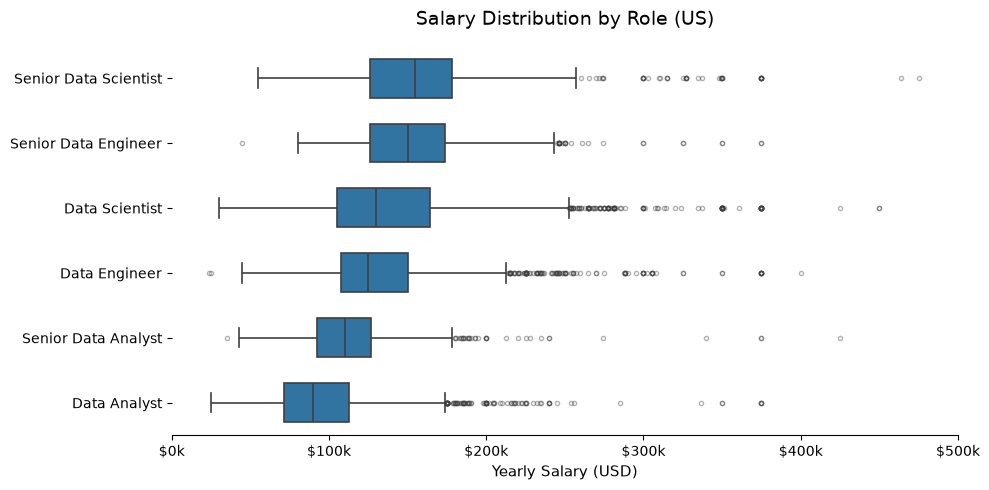

In [16]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=df_US_Jobs, x='salary_year_avg', y='job_title_short',legend=False,
    width=0.6,
    linewidth=1.2,
    flierprops={'marker': 'o', 'markersize': 3, 'alpha': 0.4},
    ax=ax, order=Job_Order)
ax.set_title('Salary Distribution by Role (US)', fontsize=14, pad=15)
ax.set_xlabel('Yearly Salary (USD)', fontsize=11)
ax.set_ylabel('')

ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${int(x/1000)}k'))
ax.set_xlim(0, 500000)  # trims extreme outliers so the boxes are readable

sns.despine(left=True)
plt.tight_layout()
plt.show()